# Dark Pattern Detector: spotting manipulative tricks on shopping sites
**Veritas AI International High School Hackathon 2026 · Track: AI + Finance**
**Team:** Viraaj Burli, Rishi Datta, Neil Todkar

> **One-sentence pitch:** Our tool helps **teenagers shopping online with their first debit card** by taking **text from a product or checkout page** and giving back **which phrases are manipulative tricks (fake urgency, fake scarcity, pressure from "other shoppers", guilt-trip buttons) and what each trick is trying to make them do.**

**Our own question:** a published model gets ~97% accuracy on dark patterns collected from shopping sites in **2019**. *Does a model trained on that 2019 data still work on dark patterns gathered **independently, years later, by a different team** (a 2024 dataset built mostly from Indian shopping, travel and subscription sites), and if not, can we fix it?*

*This project is a prototype and is not financial advice.*

---
**How to use this notebook:** File → Save a copy in Drive, then Runtime → Run all. Each part explains what it does and why. Everything runs without any uploads.

## Part 0: Setup
Installs the demo library and imports everything we need. Fixing `RANDOM_STATE` means we get the same split every time, so our results are reproducible.

In [1]:
!pip install -q --root-user-action=ignore gradio

import os, re, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import GroupShuffleSplit, train_test_split, GroupKFold, cross_val_predict
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.pipeline import make_pipeline, FeatureUnion
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, precision_score, recall_score, f1_score,
                             ConfusionMatrixDisplay, precision_recall_curve, roc_auc_score, cohen_kappa_score)
warnings.filterwarnings("ignore")
pd.set_option("display.max_colwidth", 120)
RANDOM_STATE = 42
print("Ready ✅")

Ready ✅


## Part 1: Load the data
**Dataset:** Yada et al. (2022), *Dark patterns in e-commerce: a dataset and its baseline evaluations*. It takes the 1,818 dark-pattern texts that Mathur et al. (2019) found on 1,254 shopping sites, and adds normal (non-manipulative) text from the same sites.

Columns: `page_id` (which page the text came from), `text`, `label` (1 = dark pattern, 0 = normal) and `Pattern Category` (the type of trick).

In [2]:
DATA_URL = "https://raw.githubusercontent.com/yamanalab/ec-darkpattern/master/dataset/dataset.tsv"

try:
    raw = pd.read_csv(DATA_URL, sep="\t")
except Exception as e:
    print("Couldn't download the dataset:", e)
    print("Download dataset.tsv from https://github.com/yamanalab/ec-darkpattern and upload it:")
    from google.colab import files
    uploaded = files.upload()
    raw = pd.read_csv(next(iter(uploaded)), sep="\t")

df = raw.rename(columns={"Pattern Category": "category"})
df["text"] = df["text"].astype(str).str.strip()
df = df[df["text"].str.len() > 0]

# Remove exact duplicate texts so the same sentence can't appear in both train and test
n_before = len(df)
conflicts = df.groupby("text")["label"].nunique()
df = df[~df["text"].isin(conflicts[conflicts > 1].index)]   # same text with both labels: drop it
df = df.drop_duplicates(subset="text").reset_index(drop=True)
print(f"{n_before} rows -> {len(df)} after removing empty/duplicate/conflicting texts")
df.sample(8, random_state=1)

2356 rows -> 2349 after removing empty/duplicate/conflicting texts


,page_id,text,label,category
846,1044,PG Picks: Skin Care for Incontinence,0,Not Dark Pattern
674,1736,Report a Fake Product,0,Not Dark Pattern
1703,1026,Stone Cold Steve Austin,0,Not Dark Pattern
292,179,2 viewed per hour,1,Social Proof
285,1038,AdjustableBucketHeadbandsSale Items- View All -,0,Not Dark Pattern
1290,559,01 Hours 37 Minutes 48 Seconds 1/10s,1,Urgency
1450,132,Someone in Keilor East bought a Piranta-Edge Skinning Knife - Blaze - Havalon Knives54 minutes ago,1,Social Proof
650,808,OFFER ENDS 00:54:59,1,Urgency


## Part 2: Explore before modelling
Before modelling we check how balanced the data is, which trick types exist, and whether anything looks suspicious.

Label balance (1 = dark pattern):
label
1    1178
0    1171
Name: count, dtype: int64 

Trick types among dark patterns:
category
Scarcity         418
Social Proof     312
Urgency          210
Misdirection     195
Obstruction       27
Sneaking          12
Forced Action      4
Name: count, dtype: int64


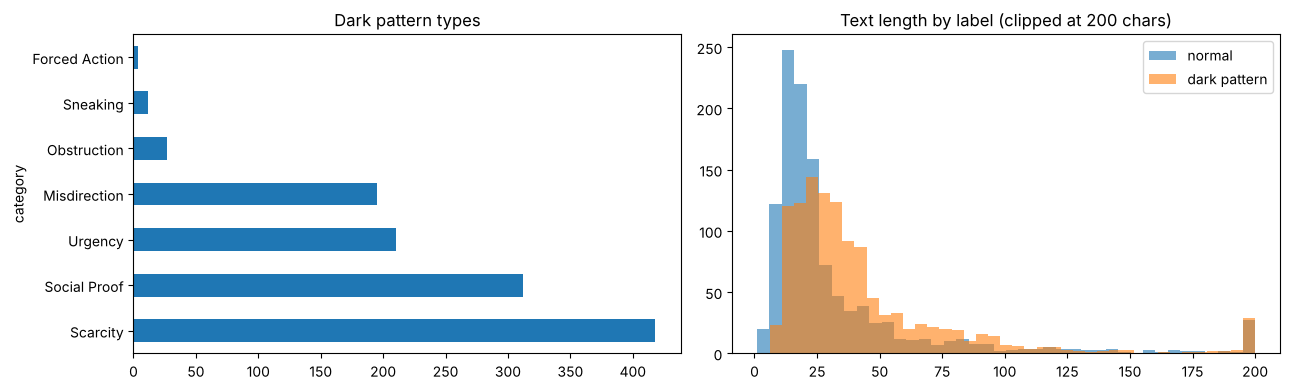

In [3]:
print("Label balance (1 = dark pattern):")
print(df["label"].value_counts(), "\n")
print("Trick types among dark patterns:")
print(df.loc[df.label == 1, "category"].value_counts())

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
df.loc[df.label == 1, "category"].value_counts().plot(kind="barh", ax=axes[0], title="Dark pattern types")
df["n_chars"] = df["text"].str.len()
for lab, name in [(0, "normal"), (1, "dark pattern")]:
    axes[1].hist(df.loc[df.label == lab, "n_chars"].clip(upper=200), bins=40, alpha=0.6, label=name)
axes[1].set_title("Text length by label (clipped at 200 chars)"); axes[1].legend()
plt.tight_layout(); plt.show()

**What to notice:** some trick types (Obstruction, Sneaking, Forced Action) have very few examples, so the model will be weak on them. Write this down as a limitation.

If the two length histograms look very different, a model could "cheat" by learning *text length* instead of *manipulation*. We test this directly in Part 4.

**Label check:** we read the 20 random rows below to check the labels by eye.

In [4]:
df.sample(20, random_state=7)[["text", "label", "category"]]

,text,label,category
1779,"An item you ordered is in high demand. No worries, we have prioritized your order.",1,Scarcity
1051,30 people have purchased this item,1,Social Proof
2,Write a review,0,Not Dark Pattern
1596,Free Shipping & Easy Returns always!,0,Not Dark Pattern
672,Explosive Offers! 80% Off Everything 07:25:41,1,Urgency
328,Only 1 left in Stock,1,Scarcity
1690,FLASH 19:15:22,1,Urgency
2162,Complete your purchase within the next 12:18 minutes and receive 10% off,1,Urgency
204,Limited stock Only 2 left,1,Scarcity
658,HURRY! 3 left in stock!,1,Scarcity


## Part 3: Split the data fairly
We hold out 20% of the data as a **test set** the model never sees during training.

**We split by `page_id`, not randomly.** Text from the same page often repeats with small changes ("Only 3 left" / "Only 2 left"). A random split would put near-copies in both train and test and make the model look better than it is. Splitting by page means every test example comes from pages the model has never seen.

In [5]:
gss = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=RANDOM_STATE)
train_idx, test_idx = next(gss.split(df, df["label"], groups=df["page_id"]))
train_df, test_df = df.iloc[train_idx].reset_index(drop=True), df.iloc[test_idx].reset_index(drop=True)

assert set(train_df.page_id).isdisjoint(set(test_df.page_id)), "a page leaked into both sets!"
print(f"Train: {len(train_df)} rows from {train_df.page_id.nunique()} pages")
print(f"Test:  {len(test_df)} rows from {test_df.page_id.nunique()} pages")
print("Share of dark patterns, train: %.2f, test: %.2f" % (train_df.label.mean(), test_df.label.mean()))
X_train, y_train = train_df["text"], train_df["label"]
X_test,  y_test  = test_df["text"],  test_df["label"]

Train: 1879 rows from 998 pages
Test:  470 rows from 250 pages
Share of dark patterns, train: 0.50, test: 0.50


## Part 4: Baselines (the simple guesses our model has to beat)
1. **Majority class:** always predict the most common label.
2. **Keyword rule:** flag any text containing pressure words like "only ... left", "hurry", "people viewing". This is what a non-AI tool would do.
3. **Shortcut check:** a model that sees only *surface features* (length, digits, "!", capital letters), not the words. If this scores almost as well as our real model, the dataset has shortcuts and the published 97% is partly inflated.

We report **precision** (when we flag something, how often it's really a trick) and **recall** (what share of real tricks we catch) for the dark-pattern class, not just accuracy. We also report **balanced accuracy** (the average of the recall on tricks and the recall on normal text), which stays fair when one class is much bigger than the other: always guessing one answer scores exactly 0.5.

In [6]:
results = {}

def report(name, y_true, y_pred, store=True):
    r = {"accuracy": accuracy_score(y_true, y_pred),
         "balanced_acc": balanced_accuracy_score(y_true, y_pred),
         "precision": precision_score(y_true, y_pred, zero_division=0),
         "recall": recall_score(y_true, y_pred, zero_division=0),
         "F1": f1_score(y_true, y_pred, zero_division=0),
         "n": len(y_true)}
    if store:
        results[name] = r
    return r

# 1. Majority class
dummy = DummyClassifier(strategy="most_frequent").fit(X_train, y_train)
report("Baseline: majority class", y_test, dummy.predict(X_test))

# 2. Keyword rule
KEYWORDS = re.compile(
    r"(only \d+ left|left in stock|low stock|almost gone|selling fast|in (high )?demand|limited (time|stock|quantity)"
    r"|hurry|last chance|ends (in|soon|today|tonight)|today only|expires?|countdown|while supplies last"
    r"|\d+ (people|others|customers|shoppers)|viewing|just (bought|purchased)|bought in the last|sold out soon"
    r"|no,? thanks|i don.?t want|popular)", re.IGNORECASE)
def keyword_rule(texts):
    return np.array([1 if KEYWORDS.search(t) else 0 for t in texts])
report("Baseline: keyword rule", y_test, keyword_rule(X_test))

# 3. Surface-features-only model (shortcut check)
def surface_features(texts):
    t = pd.Series(list(texts))
    return np.c_[t.str.len(), t.str.split().str.len(), t.str.contains(r"\d").astype(int),
                 t.str.count("!"), t.apply(lambda s: sum(c.isupper() for c in s) / max(len(s), 1))]
surface = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000, class_weight="balanced"))
surface.fit(surface_features(X_train), y_train)
report("Shortcut check: surface features only", y_test, surface.predict(surface_features(X_test)))

pd.DataFrame(results).T.round(3)

,accuracy,balanced_acc,precision,recall,F1,n
Baseline: majority class,0.500,0.500,0.50,1.000,0.667,470.0
Baseline: keyword rule,0.777,0.777,1.00,0.553,0.712,470.0
Shortcut check: surface features only,0.830,0.830,0.97,0.681,0.800,470.0


## Part 5: Our model
**TF-IDF + logistic regression.** TF-IDF turns each text into numbers based on which words and letter patterns it contains. We use both **words** ("only", "left") and **character chunks** (which catch variations like "3 left" / "5 left!!"). Logistic regression then learns a weight for each feature.

Why this model: it trains in seconds, it's a strong standard choice for short texts, and its weights are **explainable**, so we can show users *why* a phrase was flagged. `class_weight="balanced"` stops it ignoring the smaller class.

In [7]:
def digits_to_zero(text):
    # "116 booked" and "305 booked" become the same pattern, "000 booked"
    return re.sub(r"\d", "0", text.lower())

def make_model(words=(1, 2), prep=None):
    features = FeatureUnion([
        ("words", TfidfVectorizer(ngram_range=words, min_df=2, sublinear_tf=True, preprocessor=prep)),
        ("chars", TfidfVectorizer(analyzer="char_wb", ngram_range=(2, 5), min_df=2, sublinear_tf=True, preprocessor=prep)),
    ])
    return make_pipeline(features, LogisticRegression(max_iter=3000, class_weight="balanced", C=4))

model = make_model().fit(X_train, y_train)
test_pred = model.predict(X_test)
report("Our model: TF-IDF + logistic regression", y_test, test_pred)
pd.DataFrame(results).T.round(3)

,accuracy,balanced_acc,precision,recall,F1,n
Baseline: majority class,0.500,0.500,0.500,1.000,0.667,470.0
Baseline: keyword rule,0.777,0.777,1.000,0.553,0.712,470.0
Shortcut check: surface features only,0.830,0.830,0.970,0.681,0.800,470.0
Our model: TF-IDF + logistic regression,0.957,0.957,0.965,0.949,0.957,470.0


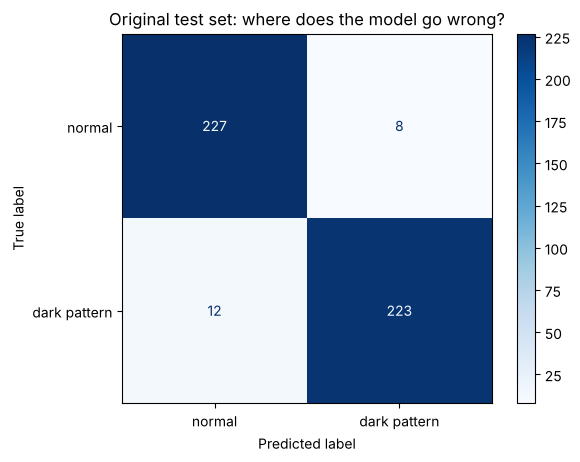

,recall,n
category,,
Forced Action,0.00,1
Sneaking,0.50,2
Misdirection,0.86,42
Obstruction,0.88,8
Social Proof,0.97,67
Urgency,0.97,34
Scarcity,1.00,81


In [8]:
ConfusionMatrixDisplay.from_predictions(y_test, test_pred, display_labels=["normal", "dark pattern"], cmap="Blues")
plt.title("Original test set: where does the model go wrong?"); plt.show()

# Recall for each trick type: which tricks do we catch, which do we miss?
test_dark = test_df[test_df.label == 1].copy()
test_dark["caught"] = model.predict(test_dark["text"])
per_cat = test_dark.groupby("category")["caught"].agg(recall="mean", n="size").sort_values("recall")
per_cat.round(2)

### Where does it fail?
Below are the model's real mistakes on the test set. Our explanation of each kind of mistake is in the README under *Where it fails*.

In [9]:
test_df["p_dark"] = model.predict_proba(X_test)[:, 1]
print("❌ MISSED tricks (false negatives), lowest-confidence first:")
display(test_df[(test_df.label == 1) & (test_df.p_dark < 0.5)].sort_values("p_dark")[["text", "category", "p_dark"]].head(8))
print("⚠️ FALSE ALARMS (normal text flagged as a trick):")
display(test_df[(test_df.label == 0) & (test_df.p_dark >= 0.5)].sort_values("p_dark", ascending=False)[["text", "p_dark"]].head(8))

❌ MISSED tricks (false negatives), lowest-confidence first:


,text,category,p_dark
368,SUPPORT THE AMERICAN SUPRESSOR ASSOCIATION,Sneaking,0.019367
262,I agree to receive marketing emails from Natural Life and agree to our Privacy Policy and terms of use.,Forced Action,0.092678
30,I'll Shop Without A Discount,Misdirection,0.093660
43,"Long Dress Style Beach Cover Up With Lace Detail Jessica in Metairie, United States",Social Proof,0.174678
147,Don't forget the essentials Get up to 2 years of accidental damage coverage with AppleCare+.,Misdirection,0.184892
385,"THE COMPETITION $1,299.99",Misdirection,0.323987
438,Would you like to buy more and save more?,Misdirection,0.350304
72,"Our most recent customers are from New Rochelle, Roseville, and Brooksville",Social Proof,0.370816


⚠️ FALSE ALARMS (normal text flagged as a trick):


,text,p_dark
277,Sorry! This product is no longer available,0.930926
391,cm in,0.919533
411,Most of our orders are from repeat customers.,0.713253
232,"Products are automatically delivered on your schedule. No obligation, modify or cancel your subscription anytime.",0.624131
321,You might also like,0.593039
154,Price Low To High,0.561290
212,These pieces are not yet in stock but will be shipped as soon as they are available. The estimated ship date will be...,0.540415
266,Businesses in the EU buying from a business in the same country are also charged VAT.,0.523331


### What did the model learn?
These are the words that push a text most strongly towards "dark pattern" or "normal". If the "normal" list is full of things like product names or menu words, the model is partly learning *what normal shop text looks like* rather than *what manipulation looks like*.

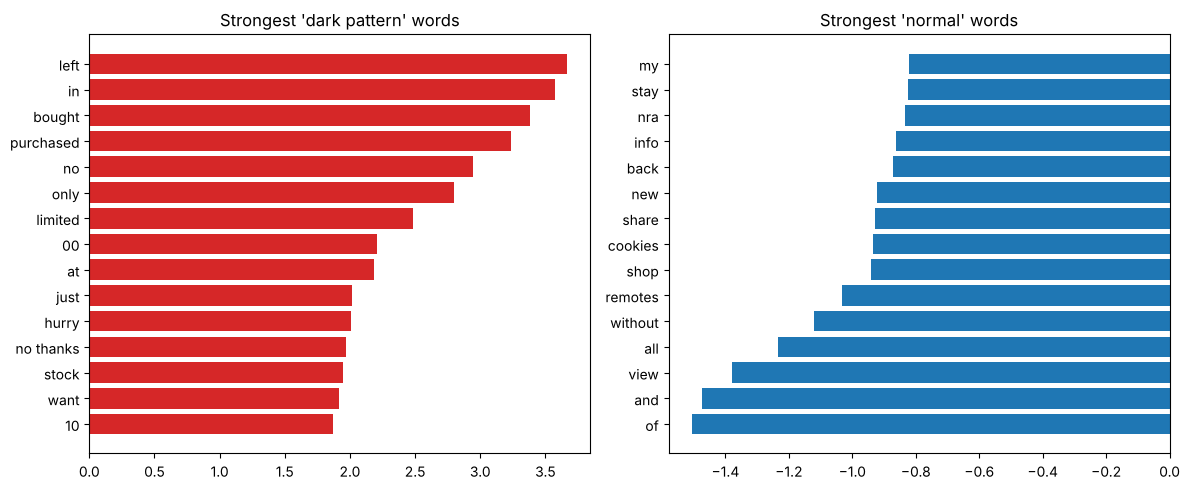

In [10]:
words_vec = model.named_steps["featureunion"].transformer_list[0][1]
names = words_vec.get_feature_names_out()
coefs = model.named_steps["logisticregression"].coef_[0][:len(names)]
order = np.argsort(coefs)
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
axes[0].barh(names[order[-15:]], coefs[order[-15:]], color="tab:red");  axes[0].set_title("Strongest 'dark pattern' words")
axes[1].barh(names[order[:15]],  coefs[order[:15]],  color="tab:blue"); axes[1].set_title("Strongest 'normal' words")
plt.tight_layout(); plt.show()

### Experiment: does splitting by page matter?
We train the same model on a **random** split to see how much a careless split would inflate our score. A big gap would be evidence of leakage. (Result: the gap is small, so leakage is not inflating our numbers much on this data.)

In [11]:
Xr_tr, Xr_te, yr_tr, yr_te = train_test_split(df["text"], df["label"], test_size=0.2,
                                              stratify=df["label"], random_state=RANDOM_STATE)
random_split = report("(comparison) same model, RANDOM split", yr_te, make_model().fit(Xr_tr, yr_tr).predict(Xr_te), store=False)
page_split = results["Our model: TF-IDF + logistic regression"]
print(f"F1 with random split:  {random_split['F1']:.3f}")
print(f"F1 with page split:    {page_split['F1']:.3f}   <- the honest number we report")

F1 with random split:  0.940
F1 with page split:    0.957   <- the honest number we report


### Choosing the decision threshold
By default a text is flagged when the model is ≥50% sure. For a teen shopper, **missing a trick costs money** but **too many false alarms make people ignore the tool**.

We pick the threshold using **cross-validation on the training data only** (never the test set), aiming to catch at least 90% of tricks with the best possible precision. We chose 90% because for a teen with limited money, a missed trick (they overspend) is worse than an occasional false alarm.

Chosen threshold: 0.70


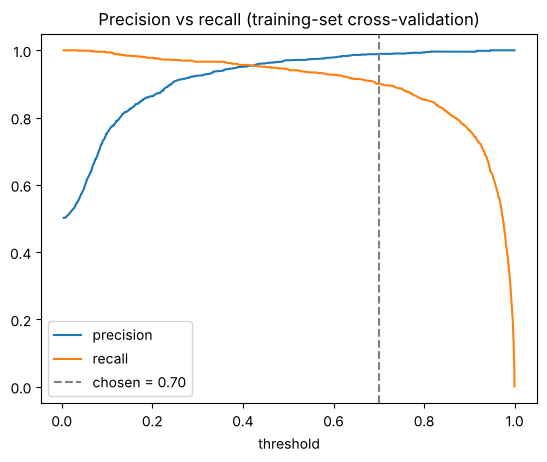

,accuracy,balanced_acc,precision,recall,F1,n
Baseline: majority class,0.500,0.500,0.500,1.000,0.667,470.0
Baseline: keyword rule,0.777,0.777,1.000,0.553,0.712,470.0
Shortcut check: surface features only,0.830,0.830,0.970,0.681,0.800,470.0
Our model: TF-IDF + logistic regression,0.957,0.957,0.965,0.949,0.957,470.0
"Our model, threshold 0.70",0.947,0.947,0.986,0.906,0.945,470.0


In [12]:
TARGET_RECALL = 0.90
cv_proba = cross_val_predict(make_model(), X_train, y_train, groups=train_df["page_id"],
                             cv=GroupKFold(n_splits=5), method="predict_proba")[:, 1]
prec, rec, thr = precision_recall_curve(y_train, cv_proba)
ok = np.where(rec[:-1] >= TARGET_RECALL)[0]
THRESHOLD = float(thr[ok[np.argmax(prec[:-1][ok])]]) if len(ok) else 0.5
print(f"Chosen threshold: {THRESHOLD:.2f}")

plt.plot(thr, prec[:-1], label="precision"); plt.plot(thr, rec[:-1], label="recall")
plt.axvline(THRESHOLD, color="gray", ls="--", label=f"chosen = {THRESHOLD:.2f}")
plt.xlabel("threshold"); plt.legend(); plt.title("Precision vs recall (training-set cross-validation)"); plt.show()

report(f"Our model, threshold {THRESHOLD:.2f}", y_test, (test_df["p_dark"] >= THRESHOLD).astype(int))
pd.DataFrame(results).T.round(3)

## Part 6: Naming the trick
Flagging a phrase isn't enough. Users learn more if we say *which* trick it is. A second classifier, trained only on dark patterns, predicts the trick type. Rare types are grouped as "Other trick" because there are too few examples to learn them.

In [13]:
MIN_EXAMPLES = 20
def group_rare(cats, common):
    return cats.where(cats.isin(common), "Other trick")

cat_counts = train_df.loc[train_df.label == 1, "category"].value_counts()
COMMON_CATS = list(cat_counts[cat_counts >= MIN_EXAMPLES].index)

def make_cat_model():
    return make_pipeline(TfidfVectorizer(analyzer="char_wb", ngram_range=(2, 5), sublinear_tf=True),
                         LogisticRegression(max_iter=3000, class_weight="balanced", C=4))

tr_dark = train_df[train_df.label == 1]
cat_model = make_cat_model().fit(tr_dark["text"], group_rare(tr_dark["category"], COMMON_CATS))
te_true = group_rare(test_dark["category"], COMMON_CATS)
te_pred = cat_model.predict(test_dark["text"])
print(f"Trick-type accuracy on test dark patterns: {accuracy_score(te_true, te_pred):.1%}")
print(pd.crosstab(te_true, te_pred, rownames=["true"], colnames=["predicted"]))

Trick-type accuracy on test dark patterns: 97.0%
predicted     Misdirection  Other trick  Scarcity  Social Proof  Urgency
true                                                                    
Misdirection            37            3         0             1        1
Other trick              1           10         0             0        0
Scarcity                 0            0        80             0        1
Social Proof             0            0         0            67        0
Urgency                  0            0         0             0       34


## Part 7: A second, independent dataset: does it still work years later?
Our training data comes from a **2019** crawl of mostly US shopping sites. To test whether the model generalises, we use a **completely separate dataset built by a different team in 2024**: the CogniGuard dark-pattern dataset (Adarsh Maurya et al., MIT licence), made for India's 2023-24 *Dark Patterns Buster* hackathon. It covers newer settings such as food delivery, travel, subscriptions, cookie/privacy prompts and apps.

**We did not collect this data ourselves.** About 40% of that dataset's rows were copied from the same 2019 data we train on, so we **remove every row whose text also appears in our 2019 data** (after lower-casing and stripping punctuation). Only the genuinely new rows are used.

**Honest caveat:** many of the new rows look **written by people (or generated) rather than copied from live sites**, and many are templated near-copies of each other ("Your subscription is about to expire Renew now to continue" / "... to keep accessing"). So this is a test of *a different team's idea of what dark patterns look like*, not of live 2024 websites. We group near-copies together (same first four words) so they never end up on both sides of a train/test split in Part 8.

The file is downloaded from a fixed commit so the results are reproducible.

In [14]:
NEW_URL = ("https://raw.githubusercontent.com/4darsh-Dev/CogniGaurd/09de733f7a8d1b2a46078bfd55467f00aba1cf12/"
           "django-mlapi-backend/datasets/dp_final_dataset_may_4k.csv")
def norm(s):
    return re.sub(r"[^a-z0-9]", "", str(s).lower())

new = pd.read_csv(NEW_URL).rename(columns={"Title": "text", "Category": "category"})
new["text"] = new["text"].astype(str).str.strip()
new["category"] = new["category"].astype(str).str.strip()
new = new[new["text"].str.len() > 0]
new["label"] = (new["category"] != "Not Dark Pattern").astype(int)
print(f"CogniGuard 2024 dataset: {len(new)} rows")

# 1. Drop anything that is also in our 2019 data (theirs reused part of it)
in_2019 = new["text"].map(norm).isin(set(raw["text"].map(norm)))
print(f"Removing {in_2019.sum()} rows that also appear in the 2019 data")
new = new[~in_2019]
# 2. Drop duplicates and texts given both labels
new["key"] = new["text"].map(norm)
conf = new.groupby("key")["label"].nunique()
new = new[~new["key"].isin(conf[conf > 1].index)].drop_duplicates("key").reset_index(drop=True)
# 3. Group templated near-copies: same first four words = same group
new["group"] = new["text"].str.lower().str.replace(r"[^a-z0-9 ]", "", regex=True).str.split().str[:4].str.join(" ")
print(f"{len(new)} new rows | dark patterns: {new.label.sum()} | normal: {(new.label == 0).sum()} | near-copy groups: {new.group.nunique()}")
print("\nTrick types in the new data:")
print(new.loc[new.label == 1, "category"].value_counts())
new.sample(10, random_state=1)[["text", "category"]]

CogniGuard 2024 dataset: 4491 rows
Removing 1927 rows that also appear in the 2019 data
2195 new rows | dark patterns: 1761 | normal: 434 | near-copy groups: 1393

Trick types in the new data:
category
Urgency          562
Social Proof     361
Scarcity         309
Forced Action    231
Misdirection     196
Sneaking          74
Obstruction       28
Name: count, dtype: int64


,text,category
2143,Agreeing grants consent for AI product communications,Sneaking
306,This setting improves battery life Keep it enabled,Not Dark Pattern
1094,Trusted by leading brands bloggers authors and influencers worldwide,Social Proof
854,Last chance for off stylish summer dresses,Urgency
439,This plan is reliable and trusted Join satisfied users,Social Proof
576,A - No printouts are not required.:,Not Dark Pattern
1911,Award-winning travel brands trust our turnkey services,Social Proof
985,Surge pricing active! Book your Ola ride now before rates increase,Urgency
1205,This app will help you edit photos like a pro,Not Dark Pattern
1785,CEOs founders and influencers utilize our exclusive training,Social Proof


In [15]:
# Data quality check: how many new rows are near-copies of each other?
sizes = new.groupby("group").size().sort_values(ascending=False)
print(f"{(sizes > 1).sum()} groups have 2+ near-copies; biggest groups:")
display(sizes.head(8).rename("rows").to_frame())
print("Text length, 2019 vs new data (median characters):",
      int(df["text"].str.len().median()), "vs", int(new["text"].str.len().median()))

183 groups have 2+ near-copies; biggest groups:


,rows
group,
this setting improves your,47
this template is a,46
your project will be,31
dont want to miss,21
this is a limited,20
this app will help,20
this restaurant is a,20
this is a special,19


Text length, 2019 vs new data (median characters): 25 vs 59


In [16]:
new["p_dark"] = model.predict_proba(new["text"])[:, 1]
new_pred = (new["p_dark"] >= THRESHOLD).astype(int)
report("New data: keyword rule", new["label"], keyword_rule(new["text"]))
report("New data: majority-class baseline", new["label"], np.full(len(new), int(y_train.mode()[0])))
report("New data: our 2019-trained model (threshold 0.50)", new["label"], (new["p_dark"] >= 0.5).astype(int))
report("New data: our 2019-trained model", new["label"], new_pred)

orig = results[f"Our model, threshold {THRESHOLD:.2f}"]
now = results["New data: our 2019-trained model"]
print(f"Recall on 2019 test set: {orig['recall']:.1%}  ->  on new 2024 data: {now['recall']:.1%}")
print(f"F1     on 2019 test set: {orig['F1']:.3f}  ->  on new data: {now['F1']:.3f}")
print(f"Balanced accuracy on 2019 test set: {orig['balanced_acc']:.3f}  ->  on new data: {now['balanced_acc']:.3f}")
print("Note: 80% of the new rows are tricks, so 'always say trick' already gets F1 0.89. Balanced accuracy is the fairer comparison here.")

new_dark = new[new.label == 1].assign(caught=new_pred[new.label == 1])
print("\nRecall by trick type on new data:")
display(new_dark.groupby("category")["caught"].agg(recall="mean", n="size").sort_values("recall").round(2))
print("❌ new tricks the model MISSED:")
display(new_dark[new_dark.caught == 0][["text", "category", "p_dark"]].head(10))

Recall on 2019 test set: 90.6%  ->  on new 2024 data: 23.1%
F1     on 2019 test set: 0.945  ->  on new data: 0.371
Balanced accuracy on 2019 test set: 0.947  ->  on new data: 0.587
Note: 80% of the new rows are tricks, so 'always say trick' already gets F1 0.89. Balanced accuracy is the fairer comparison here.

Recall by trick type on new data:


,recall,n
category,,
Obstruction,0.00,28
Sneaking,0.04,74
Forced Action,0.09,231
Social Proof,0.09,361
Misdirection,0.10,196
Urgency,0.28,562
Scarcity,0.56,309


❌ new tricks the model MISSED:


,text,category,p_dark
24,Long Dress Style Beach Cover Up With Lace Detail Radhika in Haryana India,Social Proof,0.098384
40,Necessary steps are to be taken for Protection..,Misdirection,0.540007
55,I'd rather not save my product,Misdirection,0.672408
107,That’s why we spent years here at PureKana developing our premium line of 1000mg CBD oil.,Social Proof,0.207229
109,Purekana LLC is the property of Simply Better Brands Corp. © 2024 The Purekana trademark belongs to Purekana LLC.:,Misdirection,0.111777
110,Your purchase helps rescued pets with meals healthcare training and more!#1 Best seller on AmazonLoved by millions o...,Social Proof,0.335291
127,Get Best Price 1 Have a requirement,Social Proof,0.464063
133,Last chance to get free shipping,Urgency,0.636852
136,Sign in to see exclusive deals,Forced Action,0.150278
156,Expand your horizons with eBay Explore diverse categories from fashion to electronics and find hidden gems Join Oliv...,Social Proof,0.110566


## Part 8: Improvement: teach it the new tricks
We add **half** of the new dataset to training and test on the **other half**. We split by **near-copy group**, so a templated sentence and its near-copy can never be on both sides. One split could be lucky or unlucky, so we repeat with **5 different random halves** and report the average and spread.

In [17]:
rows = []
for seed in range(5):
    a_idx, h_idx = next(GroupShuffleSplit(n_splits=1, test_size=0.5, random_state=seed)
                        .split(new, new["label"], groups=new["group"]))
    adapt, hold = new.iloc[a_idx], new.iloc[h_idx]
    before = report("", hold["label"], (model.predict_proba(hold["text"])[:, 1] >= THRESHOLD).astype(int), store=False)
    m2 = make_model().fit(pd.concat([X_train, adapt["text"]]), pd.concat([y_train, adapt["label"]]))
    after = report("", hold["label"], (m2.predict_proba(hold["text"])[:, 1] >= THRESHOLD).astype(int), store=False)
    kw_r = report("", hold["label"], keyword_rule(hold["text"]), store=False)
    rows.append({"seed": seed, "recall_before": before["recall"], "recall_after": after["recall"],
                 "F1_before": before["F1"], "F1_after": after["F1"], "precision_after": after["precision"],
                 "bal_acc_before": before["balanced_acc"], "bal_acc_after": after["balanced_acc"],
                 "bal_acc_keyword": kw_r["balanced_acc"], "F1_keyword": kw_r["F1"],
                 "F1_always_trick": f1_score(hold["label"], np.ones(len(hold)))})
improve = pd.DataFrame(rows)
display(improve.round(3))
print("Average over 5 splits (± standard deviation):")
for col in ["recall_before", "recall_after", "F1_before", "F1_after", "F1_keyword", "F1_always_trick",
            "bal_acc_keyword", "bal_acc_before", "bal_acc_after"]:
    print(f"  {col:14s} {improve[col].mean():.3f} ± {improve[col].std():.3f}")
results["New data: model + half of new data (avg of 5 splits)"] = {
    "accuracy": np.nan, "balanced_acc": improve["bal_acc_after"].mean(), "precision": improve["precision_after"].mean(), "recall": improve["recall_after"].mean(),
    "F1": improve["F1_after"].mean(), "n": int(len(new) / 2)}

,seed,recall_before,recall_after,F1_before,F1_after,precision_after,bal_acc_before,bal_acc_after,bal_acc_keyword,F1_keyword,F1_always_trick
0,0,0.228,0.812,0.368,0.889,0.983,0.591,0.873,0.558,0.208,0.905
1,1,0.205,0.858,0.337,0.903,0.954,0.576,0.847,0.552,0.188,0.888
2,2,0.188,0.786,0.314,0.872,0.978,0.569,0.849,0.540,0.156,0.910
3,3,0.211,0.787,0.343,0.869,0.970,0.574,0.846,0.552,0.195,0.885
4,4,0.247,0.804,0.392,0.884,0.981,0.602,0.873,0.556,0.200,0.879


Average over 5 splits (± standard deviation):
  recall_before  0.216 ± 0.023
  recall_after   0.809 ± 0.029
  F1_before      0.351 ± 0.030
  F1_after       0.883 ± 0.014
  F1_keyword     0.190 ± 0.020
  F1_always_trick 0.893 ± 0.013
  bal_acc_keyword 0.551 ± 0.007
  bal_acc_before 0.583 ± 0.014
  bal_acc_after  0.858 ± 0.014


### How sure are we? 95% confidence intervals
A single score on a few hundred examples could be lucky. We resample each test set 1,000 times (bootstrap) and report the range that holds the middle 95% of the scores.

In [18]:

rng = np.random.default_rng(RANDOM_STATE)
def bootstrap_ci(y_true, y_pred, metric, n=1000):
    y_true, y_pred = np.asarray(y_true), np.asarray(y_pred)
    scores = [metric(y_true[idx], y_pred[idx]) for idx in (rng.integers(0, len(y_true), len(y_true)) for _ in range(n))]
    return np.percentile(scores, [2.5, 97.5])

old_pred = (test_df["p_dark"] >= THRESHOLD).astype(int)
ci_rows = []
for name, yt, yp in [("2019 test set: keyword rule", y_test, keyword_rule(X_test)),
                     ("2019 test set: our model", y_test, old_pred),
                     ("2024 data: keyword rule", new["label"], keyword_rule(new["text"])),
                     ("2024 data: our 2019-trained model", new["label"], new_pred)]:
    for mname, m in [("balanced accuracy", balanced_accuracy_score), ("recall", recall_score)]:
        lo, hi = bootstrap_ci(yt, yp, m)
        ci_rows.append({"test": name, "metric": mname, "score": m(yt, yp), "95% CI low": lo, "95% CI high": hi})
ci = pd.DataFrame(ci_rows)
ci.round(3)


,test,metric,score,95% CI low,95% CI high
0,2019 test set: keyword rule,balanced accuracy,0.777,0.746,0.807
1,2019 test set: keyword rule,recall,0.553,0.489,0.619
2,2019 test set: our model,balanced accuracy,0.947,0.926,0.964
3,2019 test set: our model,recall,0.906,0.866,0.941
4,2024 data: keyword rule,balanced accuracy,0.556,0.549,0.564
5,2024 data: keyword rule,recall,0.115,0.100,0.132
6,2024 data: our 2019-trained model,balanced accuracy,0.587,0.572,0.601
7,2024 data: our 2019-trained model,recall,0.231,0.211,0.252


### The main result in one chart

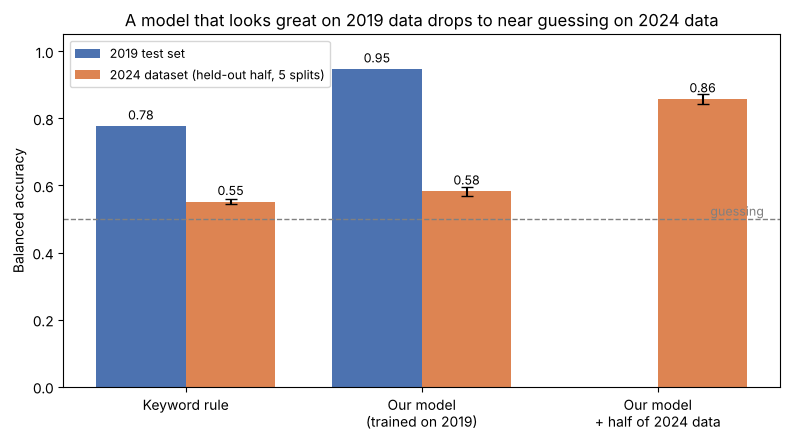

In [19]:

os.makedirs("figures", exist_ok=True)
labels = ["Keyword rule", "Our model\n(trained on 2019)", "Our model\n+ half of 2024 data"]
bal_2019 = [results["Baseline: keyword rule"]["balanced_acc"], results[f"Our model, threshold {THRESHOLD:.2f}"]["balanced_acc"], np.nan]
bal_2024 = [improve["bal_acc_keyword"].mean(), improve["bal_acc_before"].mean(), improve["bal_acc_after"].mean()]
err_2024 = [improve["bal_acc_keyword"].std(), improve["bal_acc_before"].std(), improve["bal_acc_after"].std()]
x = np.arange(len(labels)); w = 0.38
fig, ax = plt.subplots(figsize=(8, 4.5))
b1 = ax.bar(x - w/2, bal_2019, w, label="2019 test set", color="#4C72B0")
b2 = ax.bar(x + w/2, bal_2024, w, yerr=err_2024, capsize=4, label="2024 dataset (held-out half, 5 splits)", color="#DD8452")
ax.axhline(0.5, color="gray", ls="--", lw=1); ax.text(2.45, 0.51, "guessing", color="gray", ha="right", fontsize=9)
for bars in (b1, b2):
    for b in bars:
        if not np.isnan(b.get_height()):
            ax.text(b.get_x() + b.get_width()/2, b.get_height() + 0.02, f"{b.get_height():.2f}", ha="center", fontsize=9)
ax.set_xticks(x); ax.set_xticklabels(labels); ax.set_ylim(0, 1.05); ax.set_ylabel("Balanced accuracy")
ax.set_title("A model that looks great on 2019 data drops to near guessing on 2024 data")
ax.legend(loc="upper left", fontsize=9); plt.tight_layout()
plt.savefig("figures/results.png", dpi=150); plt.show()


## Part 8b: A third test: text from live websites in November 2026
The 2024 dataset was assembled by another team and many of its rows look hand-written. To check the model on **real, current pages**, we copied 176 short text snippets from public product, search, hotel, ticket and game-store pages on 15 sites (Booking.com, Agoda, Expedia, Hotels.com, Priceline, Walmart, Macy's, Temu, eBay, Fashion Nova, Steam, StubHub, Ticketmaster, GetYourGuide, Viator) on 15 November 2026, in two batches, and labelled each one using the same trick categories as the 2019 data. No personal information (names, reviews, accounts) was copied.

This set is small and realistic: only 37 of the 176 snippets (21%) are tricks, because most text on a real page is normal. Snippets were collected with AI assistance (see Sources) and labelled by one labeller, so the labels have not been checked by a second person.

We test three things: the keyword rule, our 2019-trained model, and the model retrained on the 2019 data **plus all of the 2024 dataset**.

In [20]:

LIVE_PATH = "data/live_sites_2026.csv"
LIVE_URL = "https://raw.githubusercontent.com/viraajburli-commits/dark-pattern-detector/main/data/live_sites_2026.csv"
for path in (LIVE_PATH, "../" + LIVE_PATH, LIVE_URL):
    try:
        live = pd.read_csv(path); break
    except Exception:
        continue
live["text"] = live["text"].astype(str).str.strip()
seen_before = live["text"].map(norm).isin(set(raw["text"].map(norm)) | set(new["key"]))
print(f"{len(live)} snippets from {live.source_site.nunique()} sites | tricks: {live.label.sum()} | normal: {(live.label == 0).sum()} | already in training data: {seen_before.sum()}")
live = live[~seen_before].reset_index(drop=True)

model_plus = make_model().fit(pd.concat([X_train, new["text"]]), pd.concat([y_train, new["label"]]))
live["p_2019"] = model.predict_proba(live["text"])[:, 1]
live["p_plus"] = model_plus.predict_proba(live["text"])[:, 1]
preds = {"Live sites: keyword rule": keyword_rule(live["text"]),
         "Live sites: our 2019-trained model": (live["p_2019"] >= THRESHOLD).astype(int).values,
         "Live sites: model + all 2024 data": (live["p_plus"] >= THRESHOLD).astype(int).values}
live_rows = []
for name, yp in preds.items():
    report(name, live["label"], yp)
    lo, hi = bootstrap_ci(live["label"], yp, balanced_accuracy_score)
    rlo, rhi = bootstrap_ci(live["label"], yp, recall_score)
    r = results[name]
    live_rows.append({"model": name.replace("Live sites: ", ""), "balanced_acc": r["balanced_acc"], "95% CI": f"{lo:.2f} to {hi:.2f}",
                      "precision": r["precision"], "recall": r["recall"], "recall 95% CI": f"{rlo:.2f} to {rhi:.2f}", "F1": r["F1"]})
pd.DataFrame(live_rows).round(3)


176 snippets from 15 sites | tricks: 37 | normal: 139 | already in training data: 2


,model,balanced_acc,95% CI,precision,recall,recall 95% CI,F1
0,keyword rule,0.568,0.51 to 0.63,0.833,0.143,0.03 to 0.27,0.244
1,our 2019-trained model,0.693,0.60 to 0.78,0.615,0.457,0.29 to 0.62,0.525
2,model + all 2024 data,0.764,0.68 to 0.85,0.677,0.600,0.43 to 0.76,0.636


In [21]:

live["pred_2019"] = preds["Live sites: our 2019-trained model"]
live["pred_plus"] = preds["Live sites: model + all 2024 data"]
print("Recall by trick type (2019 model / retrained model):")
display(live[live.label == 1].groupby("category")[["pred_2019", "pred_plus"]].mean().round(2).assign(n=live[live.label == 1].groupby("category").size()))
print("❌ Live tricks the 2019 model missed:")
display(live[(live.label == 1) & (live.pred_2019 == 0)][["text", "source_site", "p_2019", "p_plus"]].round(2))
print("⚠️ Normal live text flagged as a trick by either model:")
display(live[(live.label == 0) & ((live.pred_2019 == 1) | (live.pred_plus == 1))][["text", "source_site", "p_2019", "p_plus"]].round(2))


Recall by trick type (2019 model / retrained model):


,pred_2019,pred_plus,n
category,,,
Misdirection,0.00,1.00,1
Scarcity,0.47,0.73,15
Social Proof,0.55,0.36,11
Urgency,0.38,0.62,8


❌ Live tricks the 2019 model missed:


,text,source_site,p_2019,p_plus
0,77% of places to stay are unavailable for your dates on our site.,booking.com,0.32,0.58
30,Lightning deals,temu.com,0.31,0.38
32,1.7K+sold,temu.com,0.18,0.11
33,100K+sold,temu.com,0.32,0.24
74,Congratulations! You get an extra 5% OFF today.,agoda.com,0.60,0.94
77,1 still available,agoda.com,0.41,0.38
86,116 booked,agoda.com,0.11,0.05
87,305 booked,agoda.com,0.12,0.05
96,Likely to sell out,getyourguide.com,0.57,0.75
116,Last tickets,stubhub.com,0.35,0.76


⚠️ Normal live text flagged as a trick by either model:


,text,source_site,p_2019,p_plus
11,Check-in From 3:00 PM,booking.com,0.83,0.11
14,There are no extra beds available at this property.,booking.com,0.95,0.84
22,This item is final sale and cannot be returned,ebay.com,0.26,0.77
29,This item was listed in the last 3 days.,ebay.com,0.96,0.96
42,Price when purchased online,walmart.com,0.88,0.96
47,"Shipping, arrives in 3+ days",walmart.com,0.76,0.46
59,Get instant access and start playing; get involved with this game as it develops.,store.steampowered.com,0.15,0.87
60,Buy this bundle to save 10% off all 2 items!,store.steampowered.com,0.96,0.97
65,New sale items are added daily,fashionnova.com,0.64,0.81
78,Agoda earns increased commission on bookings at this property. Commission earned by Agoda affects the order of your ...,agoda.com,0.39,0.81


### Part 8c: Can a settings tweak improve accuracy?
We tried one tweak: replace every digit with 0 (so "116 booked" and "305 booked" look the same) and add word triples. We chose it using 5-fold cross-validation on the training data only (the 2019 training split plus the 2024 dataset, grouped by page or near-copy group). Then we checked it once on the held-out live-site set.

In [22]:

pool_X = pd.concat([X_train, new["text"]]).reset_index(drop=True)
pool_y = pd.concat([y_train, new["label"]]).reset_index(drop=True)
pool_g = pd.concat(["page_" + train_df["page_id"].astype(str), "group_" + new["group"]]).reset_index(drop=True)
cv_rows = []
for name, m in [("our settings: word pairs, digits kept", make_model()),
                ("tweak: digits -> 0, word triples", make_model(words=(1, 3), prep=digits_to_zero))]:
    p = cross_val_predict(m, pool_X, pool_y, groups=pool_g, cv=GroupKFold(n_splits=5), method="predict_proba")[:, 1]
    cv_rows.append({"settings": name, "ROC AUC": roc_auc_score(pool_y, p), "balanced accuracy (0.5)": balanced_accuracy_score(pool_y, p >= 0.5)})
tweak_plus = make_model(words=(1, 3), prep=digits_to_zero).fit(pool_X, pool_y)
p_live = tweak_plus.predict_proba(live["text"])[:, 1]
cv_rows[1]["live sites: balanced acc."] = balanced_accuracy_score(live["label"], p_live >= THRESHOLD)
cv_rows[0]["live sites: balanced acc."] = results["Live sites: model + all 2024 data"]["balanced_acc"]
pd.DataFrame(cv_rows).round(4)


,settings,ROC AUC,balanced accuracy (0.5),live sites: balanced acc.
0,"our settings: word pairs, digits kept",0.9755,0.9250,0.7640
1,"tweak: digits -> 0, word triples",0.9763,0.9287,0.7783


## Part 9 (optional): a stronger model
Optional comparison against **sentence embeddings**: a pretrained language model (`all-MiniLM-L6-v2`) turns each text into a vector that captures meaning, not just exact words. That might help with newer tricks worded in new ways. Set `RUN_OPTIONAL = True` to run it (takes a few minutes; a GPU helps: Runtime → Change runtime type → T4 GPU).

In [23]:
RUN_OPTIONAL = False
if RUN_OPTIONAL:
    from sentence_transformers import SentenceTransformer
    encoder = SentenceTransformer("sentence-transformers/all-MiniLM-L6-v2")
    E_train = encoder.encode(X_train.tolist(), batch_size=64, show_progress_bar=True)
    emb_clf = LogisticRegression(max_iter=3000, class_weight="balanced").fit(E_train, y_train)
    report("Sentence-embedding model (2019 test)", y_test, emb_clf.predict(encoder.encode(X_test.tolist(), batch_size=64)))
    if new is not None:
        report("New data: sentence-embedding model", new["label"], emb_clf.predict(encoder.encode(new["text"].tolist(), batch_size=64)))
    display(pd.DataFrame(results).T.round(3))

## Part 10: Final model and live demo
For the demo we retrain on **everything we have** (2019 data + all of the new 2024 data). Our *reported* results all come from the held-out tests above; this final model is just the version people would actually use.

Paste the text of a product or checkout page. The tool splits it into phrases, highlights the tricks and explains each one. In Colab, `share=True` creates a public link that also works on a phone.

In [24]:
all_text, all_label = df["text"], df["label"]
all_dark = df[df.label == 1][["text", "category"]]
all_text, all_label = pd.concat([all_text, new["text"]]), pd.concat([all_label, new["label"]])
all_dark = pd.concat([all_dark, new[new.label == 1][["text", "category"]]])
final_model = make_model().fit(all_text, all_label)
final_cat_model = make_cat_model().fit(all_dark["text"], group_rare(all_dark["category"], COMMON_CATS))

EXPLAIN = {
    "Urgency":       "⏰ **Fake urgency:** time pressure (countdowns, 'ends tonight') so you buy before comparing prices. Ask: will this deal really disappear?",
    "Scarcity":      "📦 **Scarcity pressure:** claims stock is running out ('only 2 left') to rush you. These counts are often unverifiable.",
    "Social Proof":  "👥 **Social pressure:** uses other shoppers ('14 people bought this in the last hour') to make you feel you'll miss out. Usually impossible to check.",
    "Misdirection":  "🎭 **Misdirection:** wording or design that steers your choice, like guilt-trip buttons ('No thanks, I hate saving money') or pre-selected upgrades.",
    "Obstruction":   "🚧 **Obstruction:** makes something you want (like cancelling) harder than it needs to be.",
    "Sneaking":      "🕳️ **Sneaking:** hides or adds things (extra items, fees, auto-renewing subscriptions) you didn't clearly agree to.",
    "Forced Action": "🔒 **Forced action:** makes you do something unrelated (create an account, join a list) before you can continue.",
    "Other trick":   "⚠️ **Possible manipulation:** this phrase looks like a pressure tactic. Slow down and check before you pay.",
}

def split_phrases(text):
    pieces = []
    for line in str(text).splitlines():
        pieces += [p.strip() for p in re.split(r"(?<=[.!?])\s+", line) if p.strip()]
    return pieces

def analyze_text(text, threshold=None):
    threshold = THRESHOLD if threshold is None else threshold
    phrases = split_phrases(text)
    if not phrases:
        return []
    probs = final_model.predict_proba(phrases)[:, 1]
    cats = final_cat_model.predict(phrases)
    return [{"phrase": p, "p_dark": float(pr), "flag": pr >= threshold, "category": c if pr >= threshold else None}
            for p, pr, c in zip(phrases, probs, cats)]

for r in analyze_text("Only 3 left in stock, order soon!\nFree shipping on orders over $50.\n12 people are viewing this right now."):
    print(f"{'🚩' if r['flag'] else '  '} {r['p_dark']:.2f}  {r['phrase']}  {r['category'] or ''}")

🚩 1.00  Only 3 left in stock, order soon!  Scarcity
🚩 0.75  Free shipping on orders over $50.  Urgency
🚩 0.99  12 people are viewing this right now.  Social Proof


In [25]:
import gradio as gr

def demo_fn(text, threshold):
    res = analyze_text(text, threshold)
    if not res:
        return [], "Paste some text from a shopping page first."
    highlighted = []
    for r in res:
        highlighted.append((r["phrase"], r["category"]))
        highlighted.append(("\n", None))
    flagged = [r for r in res if r["flag"]]
    if not flagged:
        summary = f"✅ No obvious tricks found in {len(res)} phrases. (The tool can miss things, so still read carefully!)"
    else:
        summary = f"### 🚩 {len(flagged)} of {len(res)} phrases look like manipulation\n"
        for r in flagged:
            summary += f"\n> **\"{r['phrase']}\"** (model confidence {r['p_dark']:.0%})\n>\n> {EXPLAIN.get(r['category'], EXPLAIN['Other trick'])}\n"
    summary += "\n\n*Prototype, not financial advice.*"
    return highlighted, summary

EXAMPLES = [
    ["Running Sneakers $129.99\nHurry! Sale ends in 02:14:37\nOnly 2 left in your size\nFree returns within 30 days\n38 people bought this in the last 24 hours", THRESHOLD],
    ["Your cart is reserved for 09:59 minutes\nAdd protection plan for $14.99 (recommended)\nNo thanks, I don't care about protecting my stuff\nContinue to checkout", THRESHOLD],
    ["Organic cotton hoodie\nAvailable in S, M, L, XL\nMachine wash cold\nShips in 3-5 business days\nAdd to cart", THRESHOLD],
]

demo = gr.Interface(
    fn=demo_fn,
    inputs=[gr.Textbox(lines=8, label="Paste text from a product or checkout page"),
            gr.Slider(0.05, 0.95, value=THRESHOLD, step=0.05, label="Sensitivity threshold (lower = flags more)")],
    outputs=[gr.HighlightedText(label="Phrases", combine_adjacent=False, show_legend=True),
             gr.Markdown(label="What we found")],
    examples=EXAMPLES,
    title="Dark Pattern Detector",
    description="Spots manipulative tricks on shopping pages before you pay. Prototype, not financial advice.",
)
# Show what the demo returns for each example (so the saved notebook has visible output)
for ex, _ in EXAMPLES:
    print("INPUT:\n" + ex + "\n\nOUTPUT:")
    print(demo_fn(ex, THRESHOLD)[1])
    print("\n" + "-" * 70 + "\n")

# Launch the live app. In Colab, share=True gives a public link you can open on your phone.
try:
    import google.colab  # noqa: F401
    demo.launch(share=True)
except ImportError:
    print("Open this notebook in Google Colab to launch the live demo app.")

INPUT:
Running Sneakers $129.99
Hurry! Sale ends in 02:14:37
Only 2 left in your size
Free returns within 30 days
38 people bought this in the last 24 hours

OUTPUT:
### 🚩 5 of 6 phrases look like manipulation

> **"Running Sneakers $129.99"** (model confidence 80%)
>
> 👥 **Social pressure:** uses other shoppers ('14 people bought this in the last hour') to make you feel you'll miss out. Usually impossible to check.

> **"Hurry!"** (model confidence 93%)
>
> ⏰ **Fake urgency:** time pressure (countdowns, 'ends tonight') so you buy before comparing prices. Ask: will this deal really disappear?

> **"Sale ends in 02:14:37"** (model confidence 91%)
>
> ⏰ **Fake urgency:** time pressure (countdowns, 'ends tonight') so you buy before comparing prices. Ask: will this deal really disappear?

> **"Only 2 left in your size"** (model confidence 100%)
>
> 📦 **Scarcity pressure:** claims stock is running out ('only 2 left') to rush you. These counts are often unverifiable.

> **"38 people bought t

## Part 11: Results summary

In [26]:
summary = pd.DataFrame(results).T[["n", "accuracy", "balanced_acc", "precision", "recall", "F1"]]
summary["n"] = summary["n"].astype(int)
print("| Model | n | Accuracy | Balanced acc. | Precision | Recall | F1 |\n|---|---|---|---|---|---|---|")
for name, r in summary.iterrows():
    print(f"| {name} | {int(r['n'])} | {'-' if pd.isna(r['accuracy']) else format(r['accuracy'], '.3f')} | {r['balanced_acc']:.3f} | {r['precision']:.3f} | {r['recall']:.3f} | {r['F1']:.3f} |")

| Model | n | Accuracy | Balanced acc. | Precision | Recall | F1 |
|---|---|---|---|---|---|---|
| Baseline: majority class | 470 | 0.500 | 0.500 | 0.500 | 1.000 | 0.667 |
| Baseline: keyword rule | 470 | 0.777 | 0.777 | 1.000 | 0.553 | 0.712 |
| Shortcut check: surface features only | 470 | 0.830 | 0.830 | 0.970 | 0.681 | 0.800 |
| Our model: TF-IDF + logistic regression | 470 | 0.957 | 0.957 | 0.965 | 0.949 | 0.957 |
| Our model, threshold 0.70 | 470 | 0.947 | 0.947 | 0.986 | 0.906 | 0.945 |
| New data: keyword rule | 2195 | 0.290 | 0.556 | 0.995 | 0.115 | 0.207 |
| New data: majority-class baseline | 2195 | 0.802 | 0.500 | 0.802 | 1.000 | 0.890 |
| New data: our 2019-trained model (threshold 0.50) | 2195 | 0.469 | 0.618 | 0.917 | 0.372 | 0.529 |
| New data: our 2019-trained model | 2195 | 0.372 | 0.587 | 0.942 | 0.231 | 0.371 |
| New data: model + half of new data (avg of 5 splits) | 1097 | - | 0.858 | 0.973 | 0.809 | 0.883 |
| Live sites: keyword rule | 174 | 0.822 | 0.568 | 0.833 

## Limitations
- Rare trick types (Obstruction, Sneaking, Forced Action) have very few training examples, so the tool is weak on them.
- The tool only reads **text**. Many tricks are visual (tiny grey "decline" links, pre-ticked boxes, fake timers) and it can't see those.
- **The model breaks on new data.** Trained on 2019 data it scores 0.947 balanced accuracy on its own test set but only 0.587 on the independent 2024 dataset, catching just 23% of its tricks. Adding half of the new data fixes most of this (0.858), but that means the tool needs regular retraining as tricks change.
- The second dataset was not collected from live sites by us. Many of its rows look hand-written or generated and templated, so it tests *another team's idea of dark patterns*, not real 2024 websites.
- The live-site test set is small (35 tricks after removing overlaps) and labelled by one labeller, so its confidence intervals are wide.
- 80% of the second dataset is tricks, so F1 is misleading there ("always say trick" gets F1 0.89). We use balanced accuracy for that comparison.
- The training data is English-only and from 2019; tricks keep changing.

## Sources and credits
- **Dataset:** Y. Yada, J. Feng, T. Matsumoto, N. Fukushima, F. Kido, H. Yamana. *Dark patterns in e-commerce: a dataset and its baseline evaluations.* IEEE BigData 2022. https://github.com/yamanalab/ec-darkpattern (arXiv: https://arxiv.org/abs/2211.06543)
- **Original dark pattern collection:** A. Mathur et al. *Dark Patterns at Scale: Findings from a Crawl of 11K Shopping Websites.* CSCW 2019. https://github.com/aruneshmathur/dark-patterns
- **Second dataset:** CogniGuard dark-pattern dataset (Adarsh Maurya et al., 2024, MIT licence). https://github.com/4darsh-Dev/CogniGaurd (file `django-mlapi-backend/datasets/dp_final_dataset_may_4k.csv`, commit `09de733`). Not collected by our team.
- **Libraries:** pandas, scikit-learn, matplotlib, Gradio, sentence-transformers (optional).
- **Pretrained model (optional part):** sentence-transformers/all-MiniLM-L6-v2 (Hugging Face).
- **Live-site test set:** text copied from public pages of 15 sites on 15 November 2026 (`data/live_sites_2026.csv`), collected with AI assistance.
- **Tools:** Google Colab; Claude (Anthropic), used as an AI assistant for coding and drafting.

*This project is a prototype and is not financial advice.*